# Fake Product Review Detection

**Goal:** classify a product review as **computer-generated (CG)** or **original, human-written (OR)** using a Bidirectional LSTM.

**Dataset:** 40,432 Amazon-style product reviews (20,216 per class) from Salminen et al. (2022), *Creating and detecting fake reviews of online products*. Each row has a product `category`, a star `rating`, a `label` (`CG` or `OR`) and the review text (`text_`).

**What the label means:** `CG` reviews were produced by a language model, `OR` reviews were written by people. The model therefore detects machine-generated text as it appears in this dataset. It is not a general detector of paid or deceptive reviews.

**Notebook outline**

1. Setup and reproducibility
2. Load the data
3. Inspect and clean the data
4. Exploratory analysis
5. Text preprocessing
6. Train / validation / test split
7. Baseline: TF-IDF + Logistic Regression
8. Tokenization and padding
9. Bidirectional LSTM model
10. Training
11. Evaluation on the test set
12. Save the model and tokenizer
13. Classify a new review
14. Conclusions and limitations

## 1. Setup and reproducibility

All imports live in one cell. A single seed is set for Python, NumPy and TensorFlow so that a re-run gives the same split and (on the same hardware) the same weights. Results can still differ slightly between CPU and GPU, or between library versions.

In [1]:
import hashlib
import json
import re
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import (LSTM, Bidirectional, Dense, Dropout,
                                     Embedding, Input)
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer, tokenizer_from_json
from wordcloud import WordCloud

SEED = 42
tf.keras.utils.set_random_seed(SEED)  # seeds Python, NumPy and TensorFlow

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Load the data

The CSV is not stored in this repository. The cell below downloads it once from the source repository, pinned to a specific commit so the file cannot change underneath us, and verifies its SHA-256 checksum. This works the same way in Google Colab and on a local machine, so no manual upload is needed.

If you already have the file, place it at `data/fake reviews dataset.csv` and the download is skipped.

In [2]:
DATA_PATH = Path("data") / "fake reviews dataset.csv"
DATA_URL = (
    "https://raw.githubusercontent.com/SayamAlt/Fake-Reviews-Detection/"
    "69f5120d143f8744df3a1596d8d11be5ac76b504/fake%20reviews%20dataset.csv"
)
DATA_SHA256 = "ea03422988824bc917b5f7217e3867e27b597c647d5261adfae73cd7a85e1e1a"

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading dataset...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

checksum = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
if checksum != DATA_SHA256:
    raise ValueError(f"Unexpected dataset checksum: {checksum}")

df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (40432, 4)


,category,rating,label,text_
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfor..."
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I..."
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and...
3,Home_and_Kitchen_5,1.0,CG,"Missing information on how to use it, but it i..."
4,Home_and_Kitchen_5,5.0,CG,Very nice set. Good quality. We have had the s...


## 3. Inspect and clean the data

First check the columns, missing values and class balance.

In [3]:
print("Columns:", df.columns.tolist())
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nReviews per label:")
print(df["label"].value_counts())

Columns: ['category', 'rating', 'label', 'text_']

Missing values per column:
category    0
rating      0
label       0
text_       0
dtype: int64

Reviews per label:
label
CG    20216
OR    20216
Name: count, dtype: int64


The dataset has no missing values and the two classes are perfectly balanced, so accuracy is a meaningful metric and no resampling is needed.

### Duplicate reviews

If the same review text appears more than once, one copy can land in the training set and another in the test set. The model would then be tested on text it has already seen, which inflates the score. Duplicates are removed **before** splitting.

In [4]:
duplicate_texts = df["text_"].duplicated().sum()
print("Duplicate review texts:", duplicate_texts)

df = df.drop_duplicates(subset="text_", keep="first").reset_index(drop=True)
print("Rows after removing duplicates:", len(df))
print(df["label"].value_counts())

Duplicate review texts: 20
Rows after removing duplicates: 40412
label
OR    20215
CG    20197
Name: count, dtype: int64


### Encode the label

The target is binary: `OR -> 0` and `CG -> 1`. The check below fails loudly if the file ever contains an unexpected label.

In [5]:
LABEL_MAP = {"OR": 0, "CG": 1}
LABEL_NAMES = ["Original (OR)", "Computer-Generated (CG)"]

df["is_cg"] = df["label"].map(LABEL_MAP)
if df["is_cg"].isnull().any():
    raise ValueError("Unexpected label found in the dataset.")
df["is_cg"] = df["is_cg"].astype(int)

for label in ["CG", "OR"]:
    print(f"\n--- {label} examples ---")
    for text in df.loc[df["label"] == label, "text_"].head(3):
        print("-", text[:160])


--- CG examples ---
- Love this!  Well made, sturdy, and very comfortable.  I love it!Very pretty
- love it, a great upgrade from the original.  I've had mine for a couple of years
- This pillow saved my back. I love the look and feel of this pillow.

--- OR examples ---
- These are just perfect, exactly what I was looking for.
- Such a great purchase can't beat it for the price
- What can you say--- cheap and it works as intended.


## 4. Exploratory analysis

How are the reviews distributed over labels and product categories?

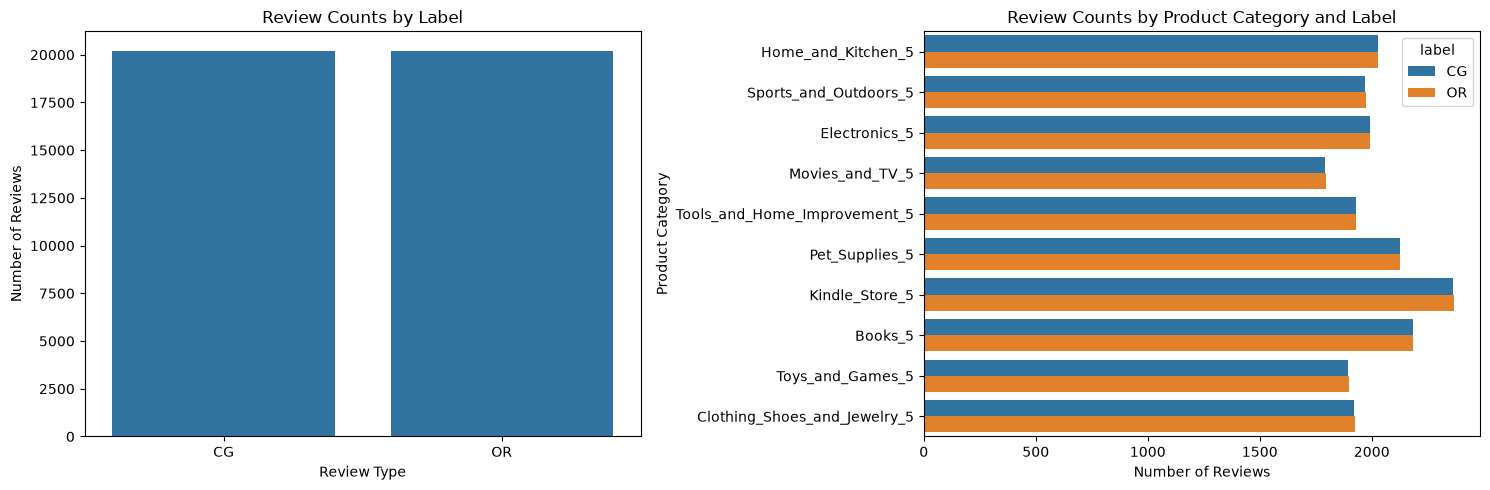

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(data=df, x="label", ax=axes[0])
axes[0].set_title("Review Counts by Label")
axes[0].set_xlabel("Review Type")
axes[0].set_ylabel("Number of Reviews")

sns.countplot(data=df, y="category", hue="label", ax=axes[1])
axes[1].set_title("Review Counts by Product Category and Label")
axes[1].set_xlabel("Number of Reviews")
axes[1].set_ylabel("Product Category")

plt.tight_layout()
plt.show()

Every category contains a similar number of `CG` and `OR` reviews, so the product category on its own does not give the label away. The model below uses only the review text; `category` and `rating` are left out on purpose so the classifier works on any review text.

## 5. Text preprocessing

Two cleaning strategies are prepared so they can be compared with evidence instead of by assumption:

| Column | What it does |
|---|---|
| `clean_light` | Lowercases the text and separates punctuation into its own tokens. **Keeps** stopwords, short words, numbers and punctuation. |
| `clean_aggressive` | Lowercases, keeps only alphabetic words of 3+ letters and removes English stopwords. |

Aggressive cleaning is common for topic-style tasks, where words like *the* and *of* carry no signal. Detecting machine-generated text is different: the signal is largely **stylistic** (function words, punctuation habits, repetition), and aggressive cleaning deletes exactly that. Section 7 measures the difference.

In [7]:
nltk.download("stopwords", quiet=True)
STOP_WORDS = set(stopwords.words("english"))


def clean_light(text):
    """Lowercase and split punctuation into separate tokens. Keeps stopwords."""
    return " ".join(re.findall(r"[a-z0-9']+|[.,!?;:]", str(text).lower()))


def clean_aggressive(text):
    """Lowercase, keep alphabetic words of 3+ letters, drop English stopwords."""
    words = re.findall(r"\b[a-z]{3,}\b", str(text).lower())
    return " ".join(word for word in words if word not in STOP_WORDS)


df["clean_light"] = df["text_"].apply(clean_light)
df["clean_aggressive"] = df["text_"].apply(clean_aggressive)

pd.set_option("display.max_colwidth", 90)
df[["text_", "clean_light", "clean_aggressive"]].sample(3, random_state=SEED)

,text_,clean_light,clean_aggressive
17115,"It works well with my old ones, as long as you keep your hands on the handle and the o...","it works well with my old ones , as long as you keep your hands on the handle and the ...",works well old ones long keep hands handle two fingers front switch
36402,I've not played the adult version of Cashflow so can't make a comparison but this game...,i've not played the adult version of cashflow so can't make a comparison but this game...,played adult version cashflow make comparison game good job teaching basic tenet rich ...
7845,"I went with the 30 minn kota for my 14 ft flat bottom, trying to save a little money. ...","i went with the 30 minn kota for my 14 ft flat bottom , trying to save a little money ...",went minn kota flat bottom trying save little money small motor decent going anywhere ...


### Review length

Review length matters for two reasons: it shows whether the two classes differ in length, and it decides how long the padded sequences need to be.

Empty reviews after cleaning: 0

Tokens per review, by label:
         count  mean   std  min   25%   50%    75%    max
label                                                    
CG     20197.0  69.0  69.3  2.0  21.0  39.0   87.0  338.0
OR     20215.0  82.7  85.4  6.0  26.0  47.0  104.0  573.0


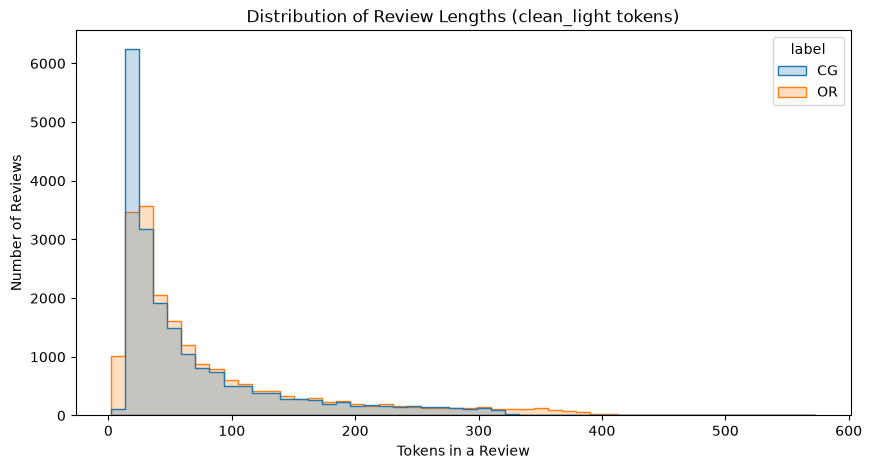

In [8]:
df["token_count"] = df["clean_light"].str.split().str.len()

print("Empty reviews after cleaning:", int((df["token_count"] == 0).sum()))
print("\nTokens per review, by label:")
print(df.groupby("label")["token_count"].describe().round(1))

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="token_count", hue="label", bins=50, element="step")
plt.title("Distribution of Review Lengths (clean_light tokens)")
plt.xlabel("Tokens in a Review")
plt.ylabel("Number of Reviews")
plt.show()

### Most frequent words per class

Word clouds use the aggressively cleaned text, because stopwords would otherwise dominate the picture.

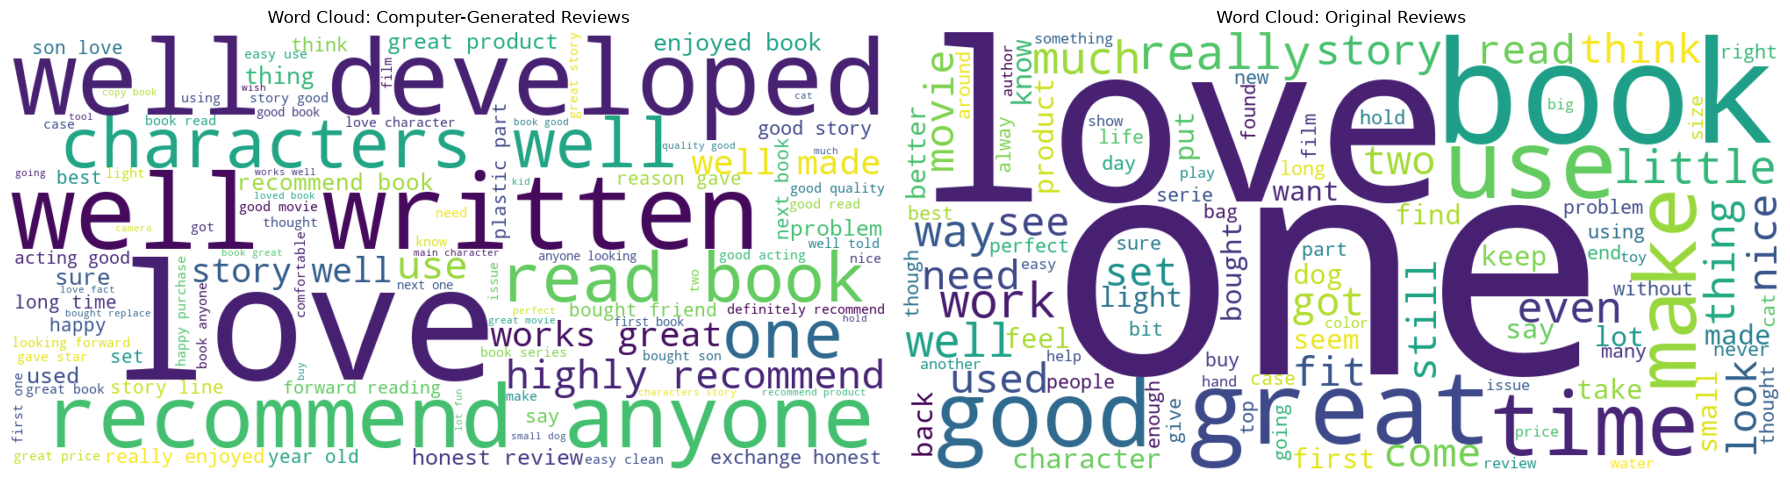

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, (label, label_name) in zip(axes, [("CG", "Computer-Generated"), ("OR", "Original")]):
    text = " ".join(df.loc[df["label"] == label, "clean_aggressive"])
    cloud = WordCloud(width=1000, height=500, background_color="white",
                      max_words=100, random_state=SEED).generate(text)
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(f"Word Cloud: {label_name} Reviews")
    ax.axis("off")
plt.tight_layout()
plt.show()

Both classes talk about the same things (*love*, *great*, *book*, *well*), which is expected because the generated reviews were made to imitate real ones. Vocabulary alone will not separate the classes cleanly; word order and style have to be used, which is what a sequence model is for.

## 6. Train / validation / test split

- **Test set (20%)**: held out and used exactly once, for the final evaluation.
- **Validation set (10% of the remaining data)**: used to compare preprocessing options and to decide when to stop training.
- **Training set**: everything else.

All splits are stratified so each keeps the 50/50 class balance. Splitting on the row index keeps both text versions aligned.

In [10]:
train_val_idx, test_idx = train_test_split(
    df.index, test_size=0.2, random_state=SEED, stratify=df["is_cg"]
)
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.1, random_state=SEED, stratify=df.loc[train_val_idx, "is_cg"]
)

y_train = df.loc[train_idx, "is_cg"].to_numpy()
y_val = df.loc[val_idx, "is_cg"].to_numpy()
y_test = df.loc[test_idx, "is_cg"].to_numpy()

for name, y in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:<11} {len(y):>6} reviews   CG share: {y.mean():.3f}")

Train        29096 reviews   CG share: 0.500
Validation    3233 reviews   CG share: 0.500
Test          8083 reviews   CG share: 0.500


## 7. Baseline: TF-IDF + Logistic Regression

A deep model is only worth its cost if it beats a simple one. The baseline is a TF-IDF bag of unigrams and bigrams fed into Logistic Regression. It trains in seconds.

The same baseline is fitted on both cleaned versions of the text, which also answers the preprocessing question from Section 5.

In [11]:
def make_baseline():
    return make_pipeline(
        TfidfVectorizer(token_pattern=r"\S+", ngram_range=(1, 2), min_df=2, sublinear_tf=True),
        LogisticRegression(max_iter=1000, random_state=SEED),
    )


baselines = {}
rows = []
for column in ["clean_aggressive", "clean_light"]:
    baseline = make_baseline().fit(df.loc[train_idx, column], y_train)
    baselines[column] = baseline
    rows.append({
        "preprocessing": column,
        "validation accuracy": accuracy_score(y_val, baseline.predict(df.loc[val_idx, column])),
    })

baseline_results = pd.DataFrame(rows).set_index("preprocessing")
baseline_results.round(4)

,validation accuracy
preprocessing,
clean_aggressive,0.9007
clean_light,0.9465


Keeping stopwords and punctuation is clearly better. In the saved run the same baseline scores about **94.7%** validation accuracy on `clean_light` against about **90.1%** on `clean_aggressive`. The tokens that aggressive cleaning removes were carrying real signal, so the rest of the notebook uses `clean_light`.

In [12]:
TEXT_COLUMN = "clean_light"

X_train_text = df.loc[train_idx, TEXT_COLUMN]
X_val_text = df.loc[val_idx, TEXT_COLUMN]
X_test_text = df.loc[test_idx, TEXT_COLUMN]

## 8. Tokenization and padding

The LSTM needs integer sequences of equal length.

- The tokenizer is **fitted on the training set only**, so no information from the validation or test set leaks into the vocabulary.
- The vocabulary is capped at the 20,000 most frequent tokens. Rarer tokens map to `<OOV>`. Rare words appear too few times to learn a useful embedding and mostly help the model memorise the training set.
- The text is already lowercased and split, so the tokenizer's own filtering is switched off (`filters=""`) to keep punctuation tokens.

In [13]:
MAX_WORDS = 20_000

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>", filters="", lower=False)
tokenizer.fit_on_texts(X_train_text)

train_sequences = tokenizer.texts_to_sequences(X_train_text)
val_sequences = tokenizer.texts_to_sequences(X_val_text)
test_sequences = tokenizer.texts_to_sequences(X_test_text)

vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)

print("Distinct tokens in the training set:", len(tokenizer.word_index))
print("Vocabulary size used by the model:", vocab_size)
print("\nExample review:", X_train_text.iloc[0][:120])
print("Encoded:", train_sequences[0][:20])

Distinct tokens in the training set: 37101
Vocabulary size used by the model: 20000

Example review: eh . generic . . get what you pay for though . why in the he do they still use flat head screws ! ha
Encoded: [6979, 2, 4225, 2, 2, 58, 83, 28, 898, 13, 302, 2, 344, 14, 3, 50, 109, 32, 121, 66]


### Choosing the sequence length

Longer sequences keep more text but make training slower. The table shows how many training reviews would be cut off at each candidate length.

In [14]:
train_lengths = np.array([len(sequence) for sequence in train_sequences])

for max_len in [100, 150, 200, 250, 300]:
    truncated = 100 * (train_lengths > max_len).mean()
    print(f"Reviews longer than {max_len} tokens: {truncated:5.2f}%")

Reviews longer than 100 tokens: 23.47%
Reviews longer than 150 tokens: 14.56%
Reviews longer than 200 tokens:  9.27%
Reviews longer than 250 tokens:  5.72%
Reviews longer than 300 tokens:  2.84%


`MAX_LEN = 300` cuts off fewer than 3% of the training reviews. A shorter limit would truncate noticeably more (about 9% at 200 tokens), and a truncated review loses its ending.

Padding is added at the end (`post`). Together with `mask_zero=True` in the embedding layer (next section), the LSTM skips the padded positions instead of reading them as input.

In [15]:
MAX_LEN = 300


def to_padded(sequences):
    return pad_sequences(sequences, maxlen=MAX_LEN, padding="post", truncating="post")


X_train = to_padded(train_sequences)
X_val = to_padded(val_sequences)
X_test = to_padded(test_sequences)

print("Train:", X_train.shape, " Validation:", X_val.shape, " Test:", X_test.shape)

Train: (29096, 300)  Validation: (3233, 300)  Test: (8083, 300)


## 9. Bidirectional LSTM model

| Layer | Purpose |
|---|---|
| `Embedding(64, mask_zero=True)` | Learns a 64-dimensional vector per token. `mask_zero=True` tells later layers to ignore padding. |
| `Bidirectional(LSTM(32))` | Reads the review left-to-right and right-to-left, so every position has context from both sides. |
| `Dense(32, relu)` + `Dropout(0.3)` | Small classification head; dropout reduces overfitting. |
| `Dense(1, sigmoid)` | Outputs the probability that the review is computer-generated. |

The loss is binary cross-entropy with the Adam optimizer.

In [16]:
model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=vocab_size, output_dim=64, mask_zero=True),
    Bidirectional(LSTM(32)),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid"),
])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,306,945 (4.99 MB)

 Trainable params: 1,306,945 (4.99 MB)

 Non-trainable params: 0 (0.00 B)

## 10. Training

Almost all of the model's parameters sit in the embedding layer, so it can memorise the training set within a few epochs. Instead of fixing the number of epochs by hand, **early stopping** watches the validation loss, stops when it has not improved for 2 epochs, and restores the weights from the best epoch.

In [17]:
early_stopping = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=64,
    epochs=10,
    callbacks=[early_stopping],
    verbose=2,
)

best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"\nBest epoch: {best_epoch} "
      f"(val_loss={min(history.history['val_loss']):.4f}, "
      f"val_accuracy={history.history['val_accuracy'][best_epoch - 1]:.4f})")

Epoch 1/10


455/455 - 33s - 72ms/step - accuracy: 0.9056 - loss: 0.2320 - val_accuracy: 0.9412 - val_loss: 0.1421


Epoch 2/10


455/455 - 31s - 68ms/step - accuracy: 0.9494 - loss: 0.1370 - val_accuracy: 0.9558 - val_loss: 0.1171


Epoch 3/10


455/455 - 31s - 68ms/step - accuracy: 0.9765 - loss: 0.0664 - val_accuracy: 0.9586 - val_loss: 0.1223


Epoch 4/10


455/455 - 30s - 67ms/step - accuracy: 0.9875 - loss: 0.0378 - val_accuracy: 0.9539 - val_loss: 0.1669



Best epoch: 2 (val_loss=0.1171, val_accuracy=0.9558)


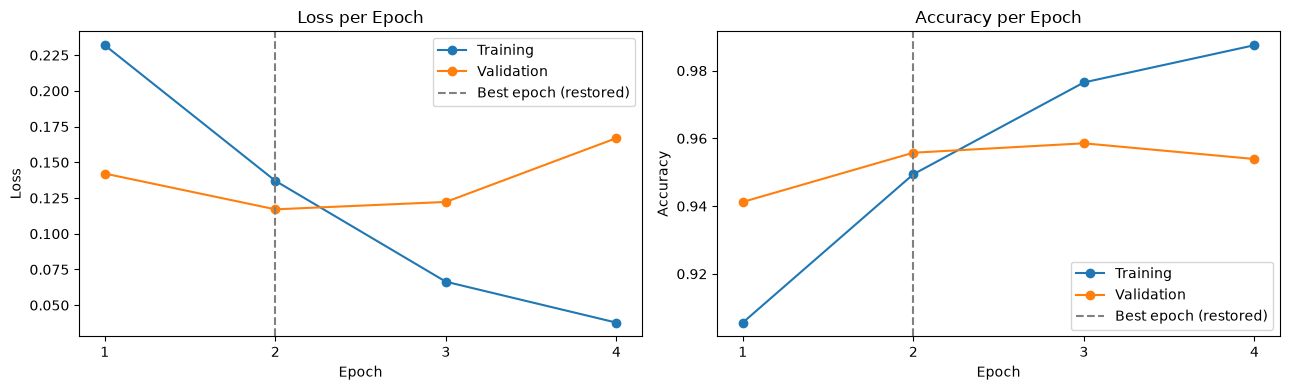

In [18]:
epochs_ran = range(1, len(history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, metric, title in [(axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy")]:
    ax.plot(epochs_ran, history.history[metric], marker="o", label="Training")
    ax.plot(epochs_ran, history.history[f"val_{metric}"], marker="o", label="Validation")
    ax.axvline(best_epoch, color="gray", linestyle="--", label="Best epoch (restored)")
    ax.set_title(f"{title} per Epoch")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.set_xticks(list(epochs_ran))
    ax.legend()

plt.tight_layout()
plt.show()

Training loss keeps falling while validation loss reaches its minimum early and then rises, which is the signature of overfitting. In the saved run the best validation loss is at epoch 2; training stops two epochs later and the weights from epoch 2 are restored. The model evaluated below is therefore the best one, not the last one.

## 11. Evaluation on the test set

The test set has not been used for any decision so far. Predictions use the standard 0.5 threshold on the predicted probability.

Test accuracy: 0.9527
Test loss:     0.1290

                         precision    recall  f1-score   support

          Original (OR)     0.9582    0.9468    0.9525      4043
Computer-Generated (CG)     0.9474    0.9587    0.9530      4040

               accuracy                         0.9527      8083
              macro avg     0.9528    0.9527    0.9527      8083
           weighted avg     0.9528    0.9527    0.9527      8083



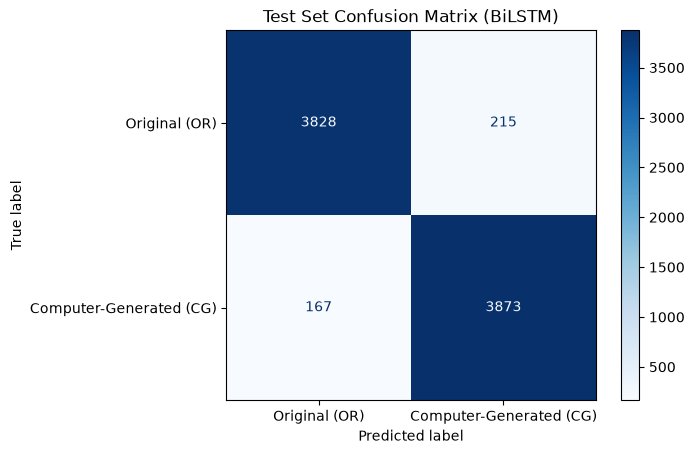

In [19]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
probabilities = model.predict(X_test, verbose=0).ravel()
predicted_labels = (probabilities >= 0.5).astype(int)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test loss:     {test_loss:.4f}\n")
print(classification_report(y_test, predicted_labels, target_names=LABEL_NAMES, digits=4))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, predicted_labels),
    display_labels=LABEL_NAMES,
).plot(cmap="Blues", values_format="d")
plt.title("Test Set Confusion Matrix (BiLSTM)")
plt.show()

### Comparison with the baseline

The baseline from Section 7 is scored on the same test set.

In [20]:
baseline_test_accuracy = accuracy_score(
    y_test, baselines[TEXT_COLUMN].predict(X_test_text)
)

comparison = pd.DataFrame(
    {"test accuracy": [baseline_test_accuracy, test_accuracy]},
    index=["TF-IDF + Logistic Regression", "Bidirectional LSTM"],
)
comparison.round(4)

,test accuracy
TF-IDF + Logistic Regression,0.9431
Bidirectional LSTM,0.9527


In the saved run the Bidirectional LSTM reaches about **95.3%** test accuracy, roughly one point above the TF-IDF baseline (about 94.3%). The two kinds of error are of similar size: about 5% of original reviews are flagged as computer-generated, and about 4% of computer-generated reviews are missed.

The gain over a model that trains in seconds is real but modest, which is worth knowing when deciding what to deploy.

## 12. Save the model and tokenizer

Three files are needed to use the model later without retraining:

- `bilstm_review_classifier.keras`: the trained model
- `tokenizer.json`: the fitted vocabulary
- `config.json`: the settings the prediction code must repeat (sequence length, threshold, label mapping)

In [21]:
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

model.save(ARTIFACT_DIR / "bilstm_review_classifier.keras")
(ARTIFACT_DIR / "tokenizer.json").write_text(tokenizer.to_json(), encoding="utf-8")
(ARTIFACT_DIR / "config.json").write_text(json.dumps({
    "max_len": MAX_LEN,
    "threshold": 0.5,
    "labels": {"0": "OR", "1": "CG"},
    "preprocessing": TEXT_COLUMN,
}, indent=2), encoding="utf-8")

for path in sorted(ARTIFACT_DIR.iterdir()):
    print(f"{path.name:<35} {path.stat().st_size / 1024:>9.1f} KB")

bilstm_review_classifier.keras        15360.7 KB
config.json                               0.1 KB
tokenizer.json                         3255.0 KB


## 13. Classify a new review

The cell below reloads everything from disk, exactly as a separate program would, and classifies a few reviews. Reloading here also proves that the saved files are complete. The same logic is available from the command line in `predict.py`.

Three of the examples come from the held-out test set, so their true labels are known. The last two are invented and have no true label.

In [22]:
loaded_model = load_model(ARTIFACT_DIR / "bilstm_review_classifier.keras")
loaded_tokenizer = tokenizer_from_json((ARTIFACT_DIR / "tokenizer.json").read_text(encoding="utf-8"))
loaded_config = json.loads((ARTIFACT_DIR / "config.json").read_text(encoding="utf-8"))


def predict_reviews(texts):
    """Return the probability that each review is computer-generated."""
    sequences = loaded_tokenizer.texts_to_sequences([clean_light(text) for text in texts])
    padded = pad_sequences(sequences, maxlen=loaded_config["max_len"],
                           padding="post", truncating="post")
    return loaded_model.predict(padded, verbose=0).ravel()


test_examples = df.loc[test_idx].groupby("label").sample(2, random_state=SEED).head(3)
examples = [(row["text_"], row["label"]) for _, row in test_examples.iterrows()]
examples += [
    ("Bought this kettle in March. The lid hinge snapped after two weeks, but support "
     "sent a replacement within three days and that one has been fine.", "unknown"),
    ("I love this product. It is a great product and I would recommend it to anyone. "
     "It is a great product and I love it.", "unknown"),
]

for (text, true_label), probability in zip(examples, predict_reviews([e[0] for e in examples])):
    predicted = loaded_config["labels"]["1" if probability >= loaded_config["threshold"] else "0"]
    print(f"P(CG) = {probability:.3f}   predicted: {predicted}   true: {true_label}")
    print(f"   {text[:110]}\n")

P(CG) = 1.000   predicted: CG   true: CG
   A friend of mine recommended this book and thought it was a great book for a beginner.  It is so easy to read 

P(CG) = 0.969   predicted: CG   true: CG
   this was a gift,my son loved it and i hope they continue to produce more of the same

P(CG) = 0.001   predicted: OR   true: OR
   These Quickstrips are perfect for throwing an extra 6 rounds each in your pocket.  The rounds come out of the 

P(CG) = 0.005   predicted: OR   true: unknown
   Bought this kettle in March. The lid hinge snapped after two weeks, but support sent a replacement within thre

P(CG) = 0.990   predicted: CG   true: unknown
   I love this product. It is a great product and I would recommend it to anyone. It is a great product and I lov



## 14. Conclusions and limitations

**Summary**

- A Bidirectional LSTM trained on lightly cleaned review text separates computer-generated from original reviews with about 95% accuracy on a held-out test set, with balanced precision and recall for both classes.
- Preprocessing mattered more than the model: keeping stopwords and punctuation was worth several points of accuracy, because the signal is stylistic.
- A TF-IDF + Logistic Regression baseline is only about one point behind, so much of the signal is available without a sequence model.
- The model overfits quickly; early stopping is what keeps the evaluated model honest.

**Limitations**

- The labels mark *machine-generated* text, not deceptive or paid reviews. A human-written fake review would be labelled `OR`.
- The computer-generated reviews come from one older text generator. Reviews written by current large language models look different, and this model has not been tested on them.
- All reviews come from one source and ten product categories. Performance on other platforms, languages or product types is unknown.
- Results come from a single train/test split and a single seed. Cross-validation or several seeds would give a confidence range.
- Only the review text is used. `rating` and `category` were left out deliberately.

**Possible next steps**

- Test on reviews generated by newer language models.
- Try pretrained embeddings or a small transformer and compare against the same baseline.
- Tune the decision threshold for the intended use, for example fewer false alarms on genuine reviews.
- Inspect misclassified reviews to see which kinds of text the model gets wrong.